# Branch A — provisional segment-weighted COM → GRF

**Goal:** reconstruct a provisional COM from the exported 12 SAM keypoints; calculate Newtonian total GRF **only after** metric global translation, gravity direction and participant mass are verified. The available export does not capture complete HAT geometry, arms, global translation or exact anthropometry. This is a **sensitivity/feasibility baseline**, not validated whole-body dynamics.

Do not change `GLOBAL_METRIC_CONFIRMED` merely to make the code run. Export root translation or establish metrically scaled camera/world coordinates first. Keep the SAM and Vicon datasets independent; Vicon is for external validation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir(): ROOT = ROOT.parent
if not (ROOT / "src").is_dir(): raise FileNotFoundError("Cannot find project root")

SUBJECT = "S1"
TRIAL = "lunge_01"
CAMERA = "cam0"
DATA_DIR = ROOT / "lunge_sam_out" / SUBJECT / TRIAL
OUT_DIR = ROOT / "results" / SUBJECT / TRIAL / "kinetics" / "branch_a" / CAMERA
OUT_DIR.mkdir(parents=True, exist_ok=True)
NPZ_PATH = DATA_DIR / f"{SUBJECT.lower()}_lunge_{CAMERA}_sam_raw.npz"

# Crucial: set to True ONLY if keypoints have been verified in a stable, metric,
# gravity-aligned global frame. Current bilateral export does NOT establish this.
GLOBAL_METRIC_CONFIRMED = False
BODY_MASS_KG = None  # Replace with participant's measured mass; e.g. 75.0
VERTICAL_AXIS = 2   # Verify with controlled movement / camera->world transform
VERTICAL_SIGN = 1.0 # +1 only if increasing coordinate = upward
SMOOTH_WINDOW_S = 0.55  # Exploratory: low-rate sampling; report sensitivity

if not NPZ_PATH.exists(): raise FileNotFoundError(NPZ_PATH)
raw = np.load(NPZ_PATH, allow_pickle=False)
print("NPZ fields:", raw.files)
t_ms = raw["time_ms"].astype(float)
frame = raw["frame_index"]
names = [str(x) for x in raw["keypoint_names"]]
xyz = raw["keypoints3d"].astype(float)
assert xyz.ndim == 3 and xyz.shape == (len(t_ms),len(names),3)
assert np.all(np.diff(t_ms)>0), "Non-increasing timestamps"
print("Frames:",len(t_ms),"dt median (ms):",np.median(np.diff(t_ms)))
print("Keys:",names)


NPZ fields: ['frame_index', 'time_ms', 'keypoint_names', 'keypoints3d', 'R_rhip_local', 'R_rknee_local', 'R_rankle_local', 'R_lhip_local', 'R_lknee_local', 'R_lankle_local']
Frames: 602 dt median (ms): 20.79868883914287
Keys: ['l_sh', 'r_sh', 'l_hip', 'r_hip', 'l_knee', 'r_knee', 'l_ankle', 'r_ankle', 'l_big_toe', 'r_big_toe', 'l_small_toe', 'r_small_toe']


## 1. Segment COM estimates

The default **illustrative** lumped fractions are deliberately transparent, not precise de Leva anthropometric data: HAT (head, arms and trunk) 67.8%, each thigh 10.0%, each shank 4.65%, each foot 1.45%. COM location fractions are also placeholders: 43.3% along thigh/shank from proximal joint; foot midpoint ankle-to-toe; HAT halfway between pelvis and shoulder midpoints. The assumed HAT location will often be wrong during arm movements and trunk flexion. **Replace these with a consistent published body-segment parameter model and full required landmarks before thesis-grade inference.**

COM shape: (602, 3)  mass weights sum: 0.9999999999999999


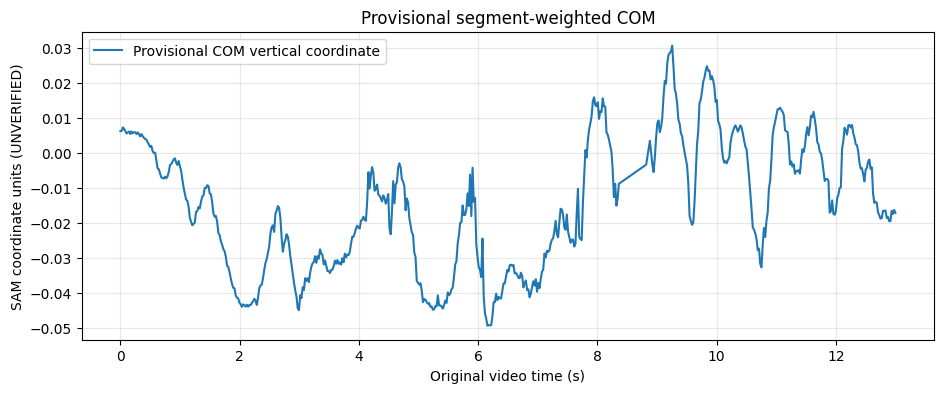

In [2]:
def kp(name):
    if name not in names: raise KeyError(f"Missing {name}; available: {names}")
    return xyz[:,names.index(name),:]

mid_hips = (kp("l_hip") + kp("r_hip")) / 2
mid_shoulders = (kp("l_sh") + kp("r_sh")) / 2
segment_com = {
    "HAT_proxy": mid_hips + 0.5 * (mid_shoulders-mid_hips),
}
fractions = {"HAT_proxy":0.678}
for side in ("l","r"):
    hip,knee,ankle = (kp(f"{side}_{j}") for j in ("hip","knee","ankle"))
    toe = (kp(f"{side}_big_toe")+kp(f"{side}_small_toe"))/2
    segment_com[f"{side}_thigh"] = hip + .433*(knee-hip)
    segment_com[f"{side}_shank"] = knee + .433*(ankle-knee)
    segment_com[f"{side}_foot"] = ankle + .5*(toe-ankle)
    fractions.update({f"{side}_thigh":.100,f"{side}_shank":.0465,f"{side}_foot":.0145})
assert np.isclose(sum(fractions.values()),1.0)
com = sum(fractions[k]*pos for k,pos in segment_com.items())
print("COM shape:",com.shape," mass weights sum:",sum(fractions.values()))

fig,ax=plt.subplots(figsize=(11,4))
ax.plot(t_ms/1000,com[:,VERTICAL_AXIS],label="Provisional COM vertical coordinate")
ax.set(xlabel="Original video time (s)",ylabel="SAM coordinate units (UNVERIFIED)",title="Provisional segment-weighted COM")
ax.grid(alpha=.3);ax.legend();plt.show()


## 2. Gap-aware smoothing and second derivatives

Savitzky–Golay differentiation assumes nearly uniform sample spacing within each uninterrupted segment. It cannot create missing high-frequency information. We split on large gaps, avoid interpolating over them, and return NaNs for segments too short for a stable fit. Test several window sizes before interpreting acceleration.

Savgol window: 27 samples = 0.562s


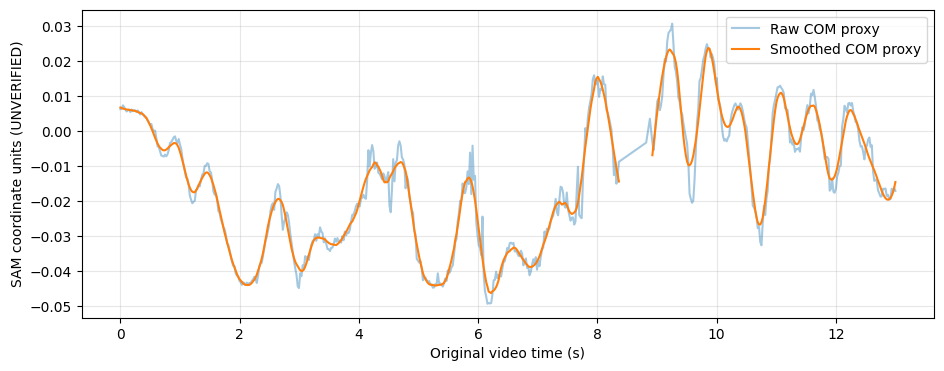

In [3]:
def smooth_and_accel(t_ms, xyz_com, window_s=0.55, polyorder=3, gap_factor=1.8):
    t=np.asarray(t_ms,dtype=float)/1000
    v=np.asarray(xyz_com,dtype=float)
    dt=np.diff(t)
    if not np.all(dt>0):raise ValueError("Times must increase")
    median_dt=float(np.median(dt))
    split=np.r_[0,np.where(dt>gap_factor*median_dt)[0]+1,len(t)]
    sm=np.full_like(v,np.nan)
    acc=np.full_like(v,np.nan)
    win=max(polyorder+2,int(round(window_s/median_dt)))
    if win%2==0:win+=1
    for a,b in zip(split[:-1],split[1:]):
        if b-a < win:continue
        tt=t[a:b]
        d=np.diff(tt)
        if np.max(np.abs(d-np.median(d))) > .02*np.median(d):
            print(f"Skipping non-uniform interval {a}:{b}")
            continue
        if not np.isfinite(v[a:b]).all():
            print(f"Skipping segment with missing coordinates {a}:{b}")
            continue
        for j in range(3):
            sm[a:b,j]=savgol_filter(v[a:b,j],win,polyorder,delta=median_dt,deriv=0)
            acc[a:b,j]=savgol_filter(v[a:b,j],win,polyorder,delta=median_dt,deriv=2)
    return sm,acc,win,median_dt

com_smooth, a_com, window_samples, dt = smooth_and_accel(t_ms,com,SMOOTH_WINDOW_S)
print(f"Savgol window: {window_samples} samples = {window_samples*dt:.3f}s")
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(t_ms/1000,com[:,VERTICAL_AXIS],alpha=.4,label="Raw COM proxy")
ax.plot(t_ms/1000,com_smooth[:,VERTICAL_AXIS],label="Smoothed COM proxy")
ax.set(xlabel="Original video time (s)",ylabel="SAM coordinate units (UNVERIFIED)")
ax.grid(alpha=.3);ax.legend();plt.show()


## 3. Newtonian GRF with mandatory verification gate

`Fz = mass * (vertical_COM_acceleration + 9.80665)` requires **metres**, **seconds**, **upward positive** and a stable **global frame**. A camera-relative pelvis-normalized reconstruction cannot be differentiated into ground reaction force. No force output is written while these conditions remain unverified.

In [4]:
if not GLOBAL_METRIC_CONFIRMED:
    print("STOP: GRF not computed. SAM global metric translation/scale/gravity alignment unverified.")
    print("You CAN inspect the COM proxy; it cannot yet be interpreted as whole-body GRF.")
else:
    if BODY_MASS_KG is None or not (20 <= float(BODY_MASS_KG) <= 300):
        raise ValueError("Enter verified participant BODY_MASS_KG")
    if VERTICAL_SIGN not in (-1.0,1.0):raise ValueError("VERTICAL_SIGN must be ±1")
    fz = float(BODY_MASS_KG)*(VERTICAL_SIGN*a_com[:,VERTICAL_AXIS]+9.80665)
    fig,ax=plt.subplots(figsize=(12,4))
    ax.plot(t_ms/1000,fz,label="SAM-derived total vertical GRF")
    ax.axhline(float(BODY_MASS_KG)*9.80665,ls="--",label="Body weight")
    ax.set(xlabel="Original video time (s)",ylabel="N",title="Exploratory SAM COM-based force")
    ax.legend();ax.grid(alpha=.3);plt.show()
    np.savez_compressed(OUT_DIR/"sam_total_grf_provisional.npz",
                        original_video_time_ms=t_ms,com_m=com,com_smooth_m=com_smooth,
                        com_accel_m_s2=a_com,total_fz_N=fz,
                        body_mass_kg=BODY_MASS_KG,smoothing_window_s=SMOOTH_WINDOW_S)


STOP: GRF not computed. SAM global metric translation/scale/gravity alignment unverified.
You CAN inspect the COM proxy; it cannot yet be interpreted as whole-body GRF.


Available fields: ['frame_index', 'time_ms', 'keypoint_names', 'keypoints3d', 'R_rhip_local', 'R_rknee_local', 'R_rankle_local', 'R_lhip_local', 'R_lknee_local', 'R_lankle_local']


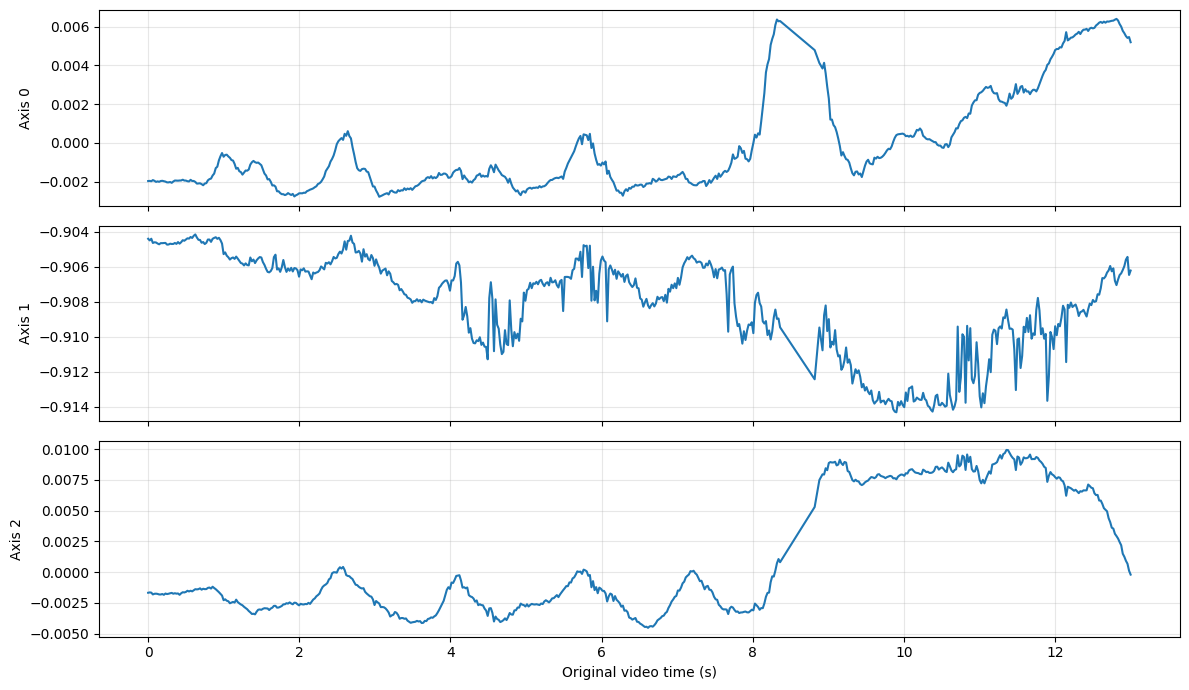

Hip midpoint range: [0.00916773 0.01017174 0.01446554]


In [7]:
print("Available fields:", raw.files)

kp = raw["keypoints3d"]
names = list(raw["keypoint_names"])

lhip = kp[:, names.index("l_hip"), :]
rhip = kp[:, names.index("r_hip"), :]

hip_mid = (lhip + rhip) / 2

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

for axis in range(3):
    axes[axis].plot(
        raw["time_ms"] / 1000,
        hip_mid[:, axis]
    )
    axes[axis].set_ylabel(f"Axis {axis}")
    axes[axis].grid(alpha=0.3)

axes[-1].set_xlabel("Original video time (s)")
plt.tight_layout()
plt.show()

print("Hip midpoint range:", np.ptp(hip_mid, axis=0))

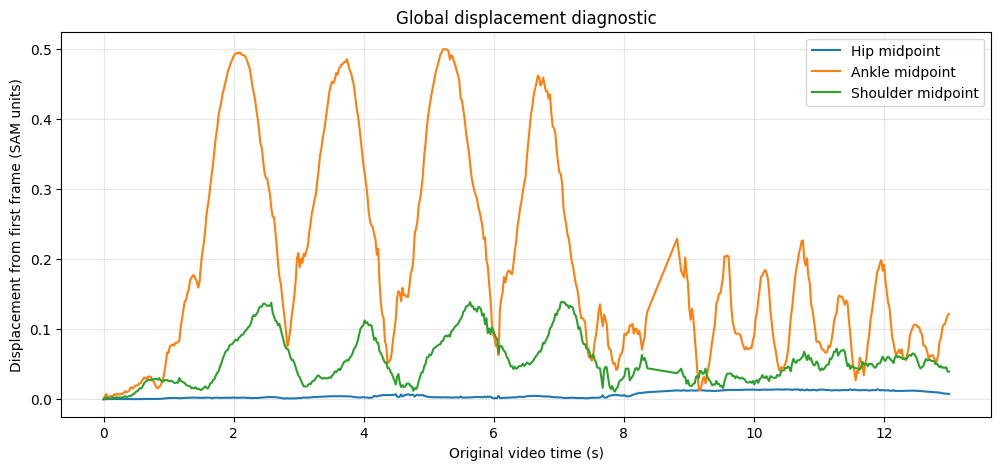

Hip midpoint range: [0.00916773 0.01017174 0.01446554]
Ankle midpoint range: [0.23492292 0.51774482 0.32523619]
Shoulder midpoint range: [0.10801253 0.09226638 0.15289452]


In [9]:
kp = raw["keypoints3d"]
names = list(raw["keypoint_names"])
t = raw["time_ms"] / 1000

def landmark(name):
    return kp[:, names.index(name), :]

hip_mid = 0.5 * (landmark("l_hip") + landmark("r_hip"))
ankle_mid = 0.5 * (landmark("l_ankle") + landmark("r_ankle"))
shoulder_mid = 0.5 * (landmark("l_sh") + landmark("r_sh"))

fig, ax = plt.subplots(figsize=(12, 5))

for label, xyz in [
    ("Hip midpoint", hip_mid),
    ("Ankle midpoint", ankle_mid),
    ("Shoulder midpoint", shoulder_mid),
]:
    displacement = np.linalg.norm(xyz - xyz[0], axis=1)
    ax.plot(t, displacement, label=label)

ax.set(
    xlabel="Original video time (s)",
    ylabel="Displacement from first frame (SAM units)",
    title="Global displacement diagnostic",
)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Hip midpoint range:", np.ptp(hip_mid, axis=0))
print("Ankle midpoint range:", np.ptp(ankle_mid, axis=0))
print("Shoulder midpoint range:", np.ptp(shoulder_mid, axis=0))

## 4. Compare to force-plate reference (only after camera synchronization)

The `bilateral_grf_reference.npz` uses the **Vicon C3D relative clock**. SAM NPZ timestamps are on the **original video clock**, so neither curves nor metrics should be compared until you have a reviewed camera-specific mapping. Also, total Vicon plate force equals whole-body GRF only during complete instrumented support. In the current trial, three force plates are assigned to contacts but uninstrumented support remains possible.

A next implementation should map `time_vicon_ms = time_video_ms + reviewed_offset_ms`, interpolate measured force onto SAM times only within overlap, and mask incomplete-support intervals. Avoid deriving the offset by maximizing GRF agreement.